# Breaking Habits: Measuring the Fragility of Household Purchasing Behavior
#### By Mattheus Marcus Contreras and Nikkei Jane Espina


### Business Context

Retailers often measure loyalty using simple statistics such as the proportion of purchases belonging to a preferred brand. However, customer habits are not always stable. Some households consistently purchase the same products over time, while others frequently switch in response to promotions, prices, or changing needs.

Rather than treating loyalty as a fixed label, this project investigates the fragility of purchasing habits. The goal is to identify households whose purchasing behavior is highly variable and therefore more susceptible to future changes.

### Research Question

1. How fragile are household purchasing habits, and which households are most likely to exhibit meaningful behavioral shifts?
2. Which households are most susceptible to changing their purchasing behavior when product availability, pricing, or assortment shifts?
3. What signals indicate that a household's purchasing habits are about to change?
4. Can we identify households on the verge of changing brands before the switch actually happens?
5. What factors trigger meaningful changes in purchasing patterns?
6. How predictable are household behavioral shifts?

In [50]:
### Section 1: Setup and Loading Data

import numpy as np
import pandas as pd
import sqlite3

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

pd.set_option("display.max_columns", None)

transactions = pd.read_csv("data/transaction_data.csv")
products = pd.read_csv("data/product.csv")
households = pd.read_csv("data/hh_demographic.csv")

conn = sqlite3.connect(":memory:")

transactions.to_sql("transactions", conn, index=False, if_exists="replace")
products.to_sql("products", conn, index=False, if_exists="replace")
households.to_sql("household", conn, index=False, if_exists="replace")

print(transactions.shape)
print(products.shape)
print(households.shape)

### Transaction Table
print(transactions.info())
print(transactions.isnull().sum())
print(transactions.duplicated().sum())
print(transactions.describe())

### Product table
print(products.info())
print(products.isnull().sum())
print(products.duplicated().sum())

##Household table
print(households.info())
print(households.isnull().sum())
print(households.duplicated().sum())


(2595732, 12)
(92353, 7)
(801, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB
None
household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0
dtype: int64
0
       household_key     BASKET_ID           DAY    PRODU

### Section 5: Data Integration
Business Question

To understand habit fragility, can transaction behavior be connected to product attributes and household demographics?

In [62]:
query = ''' 
SELECT t.*, p.manufacturer, p.department, p.brand, p.commodity_desc, p.sub_commodity_desc, p.curr_size_of_product,
h.classification_1, h.classification_2, h.classification_3, h.homeowner_desc, h.classification_5, h.classification_4,
h.kid_category_desc 
FROM transactions t
LEFT JOIN products p
ON t.product_id = p.product_id
LEFT JOIN household h
ON t.household_key = h.household_key
where classification_1 is not null
'''
df = pd.read_sql_query(query, conn)

df.shape

df.head()


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT,classification_1,classification_2,classification_3,HOMEOWNER_DESC,classification_5,classification_4,KID_CATEGORY_DESC
0,1,27601281299,51,825123,1,3.99,436,0.00,1456,8,0.0,0.0,1179,GROCERY,National,SALD DRSNG/SNDWCH SPRD,SEMI-SOLID SALAD DRESSING MAY,30 OZ,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown
1,1,27601281299,51,831447,1,2.99,436,0.00,1456,8,0.0,0.0,317,GROCERY,National,CHEESE,SHREDDED CHEESE,8 OZ,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown
2,1,27601281299,51,840361,1,1.09,436,-0.30,1456,8,0.0,0.0,69,GROCERY,Private,EGGS,EGGS - LARGE,1 DZ,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown
3,1,27601281299,51,845307,1,3.71,436,-0.62,1456,8,0.0,0.0,4084,DELI,National,DELI MEATS,MEAT: TURKEY BULK,,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown
4,1,27601281299,51,852014,1,2.79,436,-1.20,1456,8,0.0,0.0,69,GROCERY,Private,ICE CREAM/MILK/SHERBTS,TRADITIONAL,56 OZ,Age Group6,X,Level4,Homeowner,Group5,2,None/Unknown


### Section 6: Post-Join Profiling

In [63]:
## Missing Values After Merge
missing = (df.isnull().sum().sort_values(ascending=False))

print(missing[missing > 0])

print(df.duplicated().sum())
print(df.dtypes)
print(df.describe())

Series([], dtype: int64)
0
household_key             int64
BASKET_ID                 int64
DAY                       int64
PRODUCT_ID                int64
QUANTITY                  int64
SALES_VALUE             float64
STORE_ID                  int64
RETAIL_DISC             float64
TRANS_TIME                int64
WEEK_NO                   int64
COUPON_DISC             float64
COUPON_MATCH_DISC       float64
MANUFACTURER              int64
DEPARTMENT               object
BRAND                    object
COMMODITY_DESC           object
SUB_COMMODITY_DESC       object
CURR_SIZE_OF_PRODUCT     object
classification_1         object
classification_2         object
classification_3         object
HOMEOWNER_DESC           object
classification_5         object
classification_4         object
KID_CATEGORY_DESC        object
dtype: object
       household_key     BASKET_ID           DAY    PRODUCT_ID      QUANTITY  \
count   1.427303e+06  1.427303e+06  1.427303e+06  1.427303e+06  1.427303e+06   

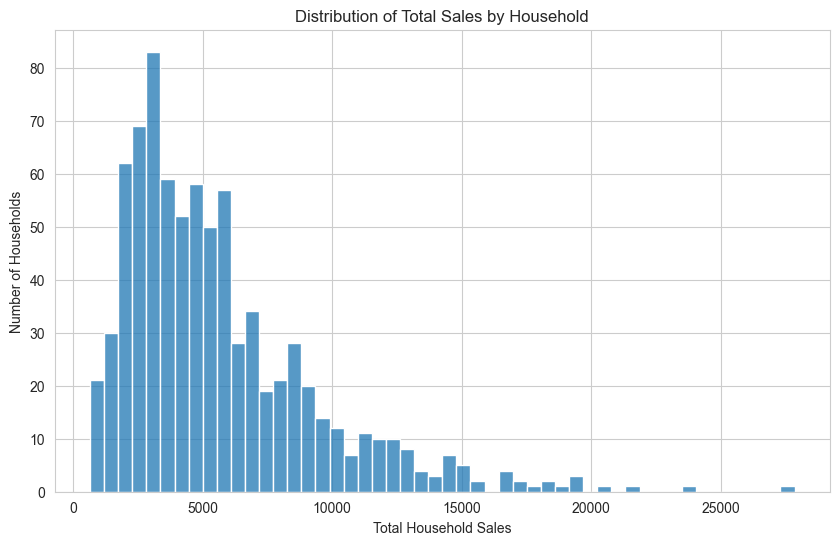

In [76]:
## Sales Value
household_sales = (
    df
    .groupby("household_key")["SALES_VALUE"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.histplot(household_sales["SALES_VALUE"], bins=50)

plt.title("Distribution of Total Sales by Household")
plt.xlabel("Total Household Sales")
plt.ylabel("Number of Households")
plt.show()

# plt.figure(figsize=(8,5))
# sns.histplot(
    # master_transactions["SALES_VALUE"],
    # bins=50
# )


The distribution of total household sales is positively skewed. Most households have relatively low to moderate total spending, while a small number of households account for substantially higher spending levels. This suggests heterogeneity in purchasing behavior, with a small segment of high-spending households potentially contributing a disproportionate share of total sales.

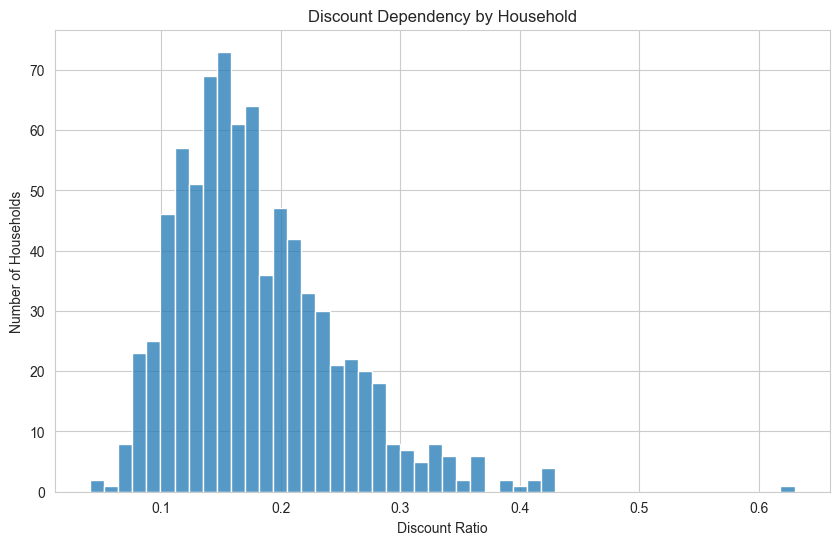

In [78]:
household_metrics = (
    df
    .groupby("household_key")
    .agg({
        "SALES_VALUE": "sum",
        "RETAIL_DISC": "sum"
    })
)

household_metrics["discount_ratio"] = (
    household_metrics["RETAIL_DISC"].abs()
    / household_metrics["SALES_VALUE"]
)

plt.figure(figsize=(10, 6))
sns.histplot(
    household_metrics["discount_ratio"],
    bins=50
)

plt.title("Discount Dependency by Household")
plt.xlabel("Discount Ratio")
plt.ylabel("Number of Households")
plt.show()

Households differ substantially in their reliance on promotions and discounts. While most households receive approximately 10% to 20% of their spending through discounts, a smaller group exhibits much higher discount dependency. These households may be more price-sensitive and therefore more likely to alter their purchasing behavior when promotions, prices, or product availability change.

### Section 7: Outlier Analysis


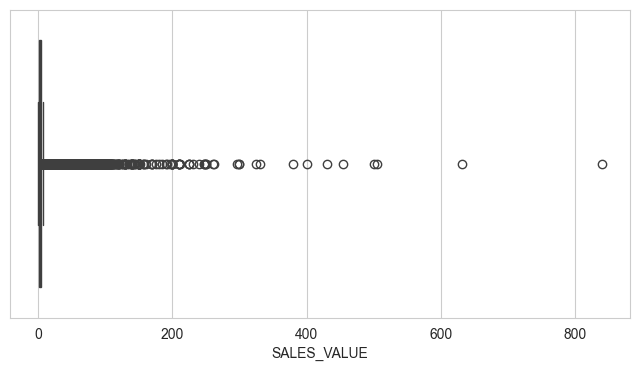

In [33]:
##Sales Value 
q1 = df["SALES_VALUE"].quantile(.25)

q3 = df["SALES_VALUE"].quantile(.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr

upper = q3 + 1.5 * iqr

sales_outliers = df[
    (df["SALES_VALUE"] < lower)
    |
    (df["SALES_VALUE"] > upper)
]

len(sales_outliers)

##Boxplot

plt.figure(figsize=(8,4))

sns.boxplot(
    x=df["SALES_VALUE"]
)

plt.show()

# Section 8: Create Analysis Dataset
### Business Question

How can household purchasing habits be represented numerically?

In [34]:
household_transactions = (
    df.groupby("household_key")
      .size()
      .reset_index(name="purchase_count")
)
household_spending = (
    df.groupby("household_key")
      ["SALES_VALUE"]
      .sum()
      .reset_index(name="total_spend")
)
household_basket = (
    df.groupby("household_key")
      ["SALES_VALUE"]
      .mean()
      .reset_index(name="average_basket")
)
coupon_usage = (
    df.groupby("household_key")
      ["COUPON_DISC"]
      .sum()
      .reset_index(name="coupon_total")
)
promo_usage = (
    df.groupby("household_key")
      ["RETAIL_DISC"]
      .sum()
      .reset_index(name="promo_total")
)
household_profile = (
    household_transactions
    .merge(household_spending,
           on="household_key")
    .merge(household_basket,
           on="household_key")
    .merge(coupon_usage,
           on="household_key")
    .merge(promo_usage,
           on="household_key")
)

household_profile.head()


,household_key,purchase_count,total_spend,average_basket,coupon_total,promo_total
0,1,1727,4330.16,2.507331,-80.56,-697.04
1,2,714,1954.34,2.737171,-9.00,-334.99
2,3,922,2653.21,2.877668,-61.19,-675.16
3,4,301,1200.11,3.987076,-2.50,-115.65
4,5,222,779.06,3.509279,0.00,-118.33


In [35]:
## Section 9: Central Tendency 

household_profile[
    [
        "purchase_count",
        "total_spend",
        "average_basket"
    ]
].mean()

household_profile[
    [
        "purchase_count",
        "total_spend",
        "average_basket"
    ]
].median()

summary = pd.DataFrame(
    {
        "Mean":
        household_profile[
            [
                "purchase_count",
                "total_spend",
                "average_basket"
            ]
        ].mean(),

        "Median":
        household_profile[
            [
                "purchase_count",
                "total_spend",
                "average_basket"
            ]
        ].median()
    }
)

summary["Mean/Median"] = (
    summary["Mean"]
    /
    summary["Median"]
)

summary

,Mean,Median,Mean/Median
purchase_count,1038.292800,734.000000,1.414568
total_spend,3222.985232,2157.750000,1.493679
average_basket,3.144357,3.014814,1.042969


In [36]:
# Section 10: Measures of Spread

household_profile[
    [
        "purchase_count",
        "total_spend",
        "average_basket"
    ]
].std()

def iqr(series):
    return (
        series.quantile(.75)
        -
        series.quantile(.25)
    )

household_profile[
    [
        "purchase_count",
        "total_spend",
        "average_basket"
    ]
].apply(iqr)

cv = (
    household_profile[
        [
            "purchase_count",
            "total_spend",
            "average_basket"
        ]
    ].std()
    /
    household_profile[
        [
            "purchase_count",
            "total_spend",
            "average_basket"
        ]
    ].mean()
)

cv


purchase_count    0.962250
total_spend       1.039107
average_basket    0.315225
dtype: float64

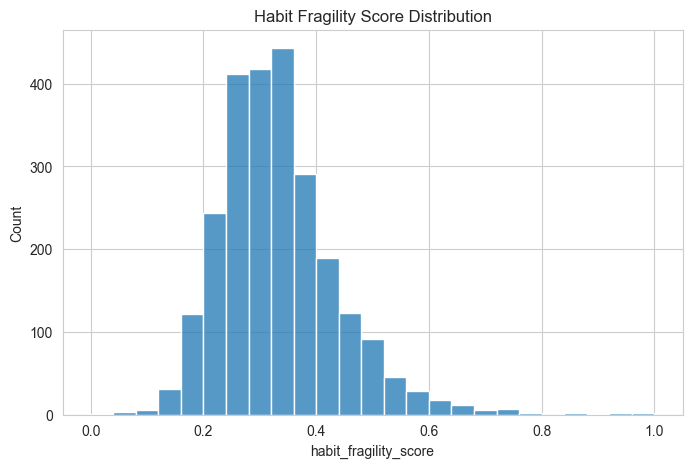

In [37]:
# Section 11: Habit Fragility Framework
weekly_spend = (
    df.groupby(
        [
            "household_key",
            "WEEK_NO"
        ]
    )
    ["SALES_VALUE"]
    .sum()
    .reset_index()
)

spend_mean = (
    weekly_spend
    .groupby("household_key")
    ["SALES_VALUE"]
    .mean()
    .reset_index(name="spend_mean")
)

spend_std = (
    weekly_spend
    .groupby("household_key")
    ["SALES_VALUE"]
    .std()
    .reset_index(name="spend_std")
)

fragility = spend_mean.merge(
    spend_std,
    on="household_key"
)

fragility["cv"] = (
    fragility["spend_std"]
    /
    fragility["spend_mean"]
)

fragility["habit_fragility_score"] = (
    (
        fragility["cv"]
        -
        fragility["cv"].min()
    )
    /
    (
        fragility["cv"].max()
        -
        fragility["cv"].min()
    )
)

fragility["fragility_level"] = pd.qcut(
    fragility["habit_fragility_score"],
    q=3,
    labels=[
        "Stable",
        "Moderately Fragile",
        "Highly Fragile"
    ]
)

plt.figure(figsize=(8,5))

sns.histplot(
    fragility["habit_fragility_score"],
    bins=25
)

plt.title(
    "Habit Fragility Score Distribution"
)

plt.show()

# Summary 

1. All source datasets were profiled before analysis.

2. Transaction, product, and demographic data were integrated
   into a unified analytical table.

3. Household purchasing behavior was summarized using
   measures of central tendency.

4. Variability was evaluated using standard deviation,
   IQR, and coefficient of variation.

5. A Habit Fragility Score was developed from household
   spending variability across time.

6. Households were classified according to behavioral
   stability and potential susceptibility to future shifts.

# Business Question

Are observed behavioral shifts genuine household behavior, or are they being distorted by missing data, outliers, and highly skewed purchasing patterns?

Section 13

#### Business Question
Before measuring habit fragility, are the underlying behavioral metrics well-behaved?

64.99212008775892
43.510000000000005


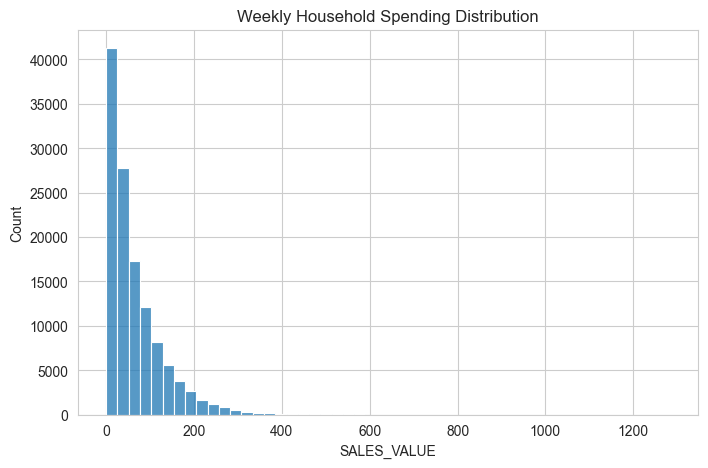

np.float64(9.431157558778507)

In [38]:
# Weekly Spend Distribution 
from scipy import stats
weekly_spend["SALES_VALUE"].describe()
mean_spend = weekly_spend["SALES_VALUE"].mean()

median_spend = weekly_spend["SALES_VALUE"].median()

print(mean_spend)
print(median_spend)

plt.figure(figsize=(8,5))

sns.histplot(
    weekly_spend["SALES_VALUE"],
    bins=50
)

plt.title(
    "Weekly Household Spending Distribution"
)

plt.show()



stats.skew(
    weekly_spend["SALES_VALUE"],
    bias=False
)
stats.kurtosis(
    weekly_spend["SALES_VALUE"],
    bias=False
)



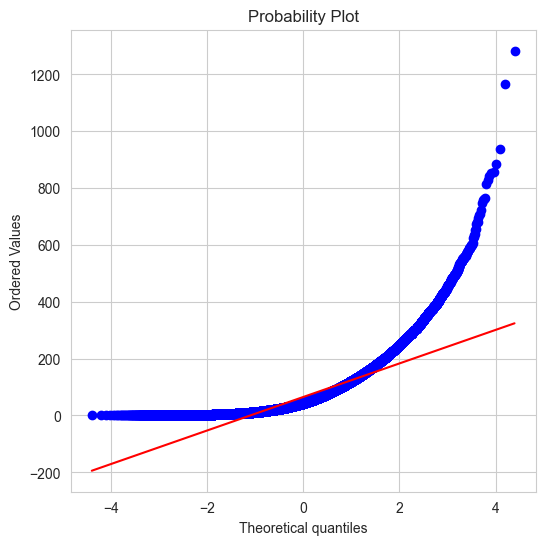

0.7977880477213078
8.507274338149466e-62


In [39]:
## Section 14
# Normality Assessment

from scipy import stats

fig, ax = plt.subplots(figsize=(6,6))

stats.probplot(
    weekly_spend["SALES_VALUE"],
    dist="norm",
    plot=ax
)

plt.show()

shapiro_stat, shapiro_p = stats.shapiro(
    weekly_spend["SALES_VALUE"]
        .sample(
            min(
                5000,
                len(weekly_spend)
            ),
            random_state=207
        )
)

print(shapiro_stat)

print(shapiro_p)

In [41]:
# Section 15: Missing Data Analysis

missing_summary = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing_summary[missing_summary > 0]

(
    df.isnull()
      .mean()
      .sort_values(ascending=False)
      * 100
).round(2)

HOMEOWNER_DESC          45.01
classification_4        45.01
classification_1        45.01
classification_3        45.01
classification_2        45.01
KID_CATEGORY_DESC       45.01
classification_5        45.01
BASKET_ID                0.00
household_key            0.00
TRANS_TIME               0.00
RETAIL_DISC              0.00
STORE_ID                 0.00
SALES_VALUE              0.00
QUANTITY                 0.00
PRODUCT_ID               0.00
DAY                      0.00
WEEK_NO                  0.00
SUB_COMMODITY_DESC       0.00
COMMODITY_DESC           0.00
BRAND                    0.00
DEPARTMENT               0.00
MANUFACTURER             0.00
COUPON_MATCH_DISC        0.00
COUPON_DISC              0.00
CURR_SIZE_OF_PRODUCT     0.00
dtype: float64

Discuss:
1. Which variables have substantial missingness?
2. Are these variables critical to habit analysis?
3. Should they be removed, retained, or imputed?

In [45]:
from scipy import stats

sales_skew = stats.skew(
    df["SALES_VALUE"],
    bias=False
)

sales_kurt = stats.kurtosis(
    df["SALES_VALUE"],
    bias=False
)

weekly_skew = stats.skew(
    weekly_spend["SALES_VALUE"],
    bias=False
)

print(f"Sales Value Skewness: {sales_skew:.2f}")
print(f"Sales Value Excess Kurtosis: {sales_kurt:.2f}")
print(f"Weekly Spend Skewness: {weekly_skew:.2f}")

print("Missing coupon values before:")
print(df["COUPON_DISC"].isna().sum())

df["COUPON_DISC"] = (
    df["COUPON_DISC"]
    .fillna(0)
)

print("\nMissing coupon values after:")
print(df["COUPON_DISC"].isna().sum())

print(f"Sales Value Skewness: {sales_skew:.2f}")
print(f"Weekly Spend Skewness: {weekly_skew:.2f}")


Sales Value Skewness: 15.91
Sales Value Excess Kurtosis: 1346.93
Weekly Spend Skewness: 2.26
Missing coupon values before:
0

Missing coupon values after:
0
Sales Value Skewness: 15.91
Weekly Spend Skewness: 2.26


Explain: 

Missing coupon discounts were replaced with zero because
the absence of a recorded coupon discount most reasonably
represents no coupon being applied rather than an unknown value.